# Winners-loosers 

In [1]:
import pandas as pd
import numpy as np
import scipy as sp

from os import listdir
from collections import OrderedDict

import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
import matplotlib as mpl

In [2]:
import sys
sys.path.append("../functions/")
import abundance_sim_analysis

In [3]:
%load_ext autoreload
%autoreload 2

**Load and process data**

In [4]:
abundances = {}
for file in listdir("../output/Venturelli2018/results_steadiercom/results_growth/"):
    if file.endswith("_abundance.tsv"):

        abundances[file.replace("_abundance.tsv","")] = pd.read_csv(f"../output/Venturelli2018/results_steadiercom/results_growth/{file}",sep="\t")

abundances_df = pd.concat(abundances)
abundances_df.reset_index(drop=True)
abundances_df.member = abundances_df.member.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())

**Filter out 1-member communities**

In [5]:
count_members_sample = abundances_df[["sample","community"]].value_counts()
count_above_1 = count_members_sample[count_members_sample>1].index
abundance_filtered = abundances_df[abundances_df[["sample", "community"]].apply(tuple, axis=1).isin(count_above_1)
].copy()

**Do a count of how often members are predicted to grow together**

In [6]:
abundance_filtered.value_counts("member")

member
CA    2907
FP    2867
EL    2580
ER    2490
CH    2163
BH    1898
DP     906
BV     838
BO     833
BT     803
BU     782
PC     574
Name: count, dtype: int64

### Co-growth count - in how many samples are two members predicted to grow together?  (NB: member1=member2 is set to 0)

[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.


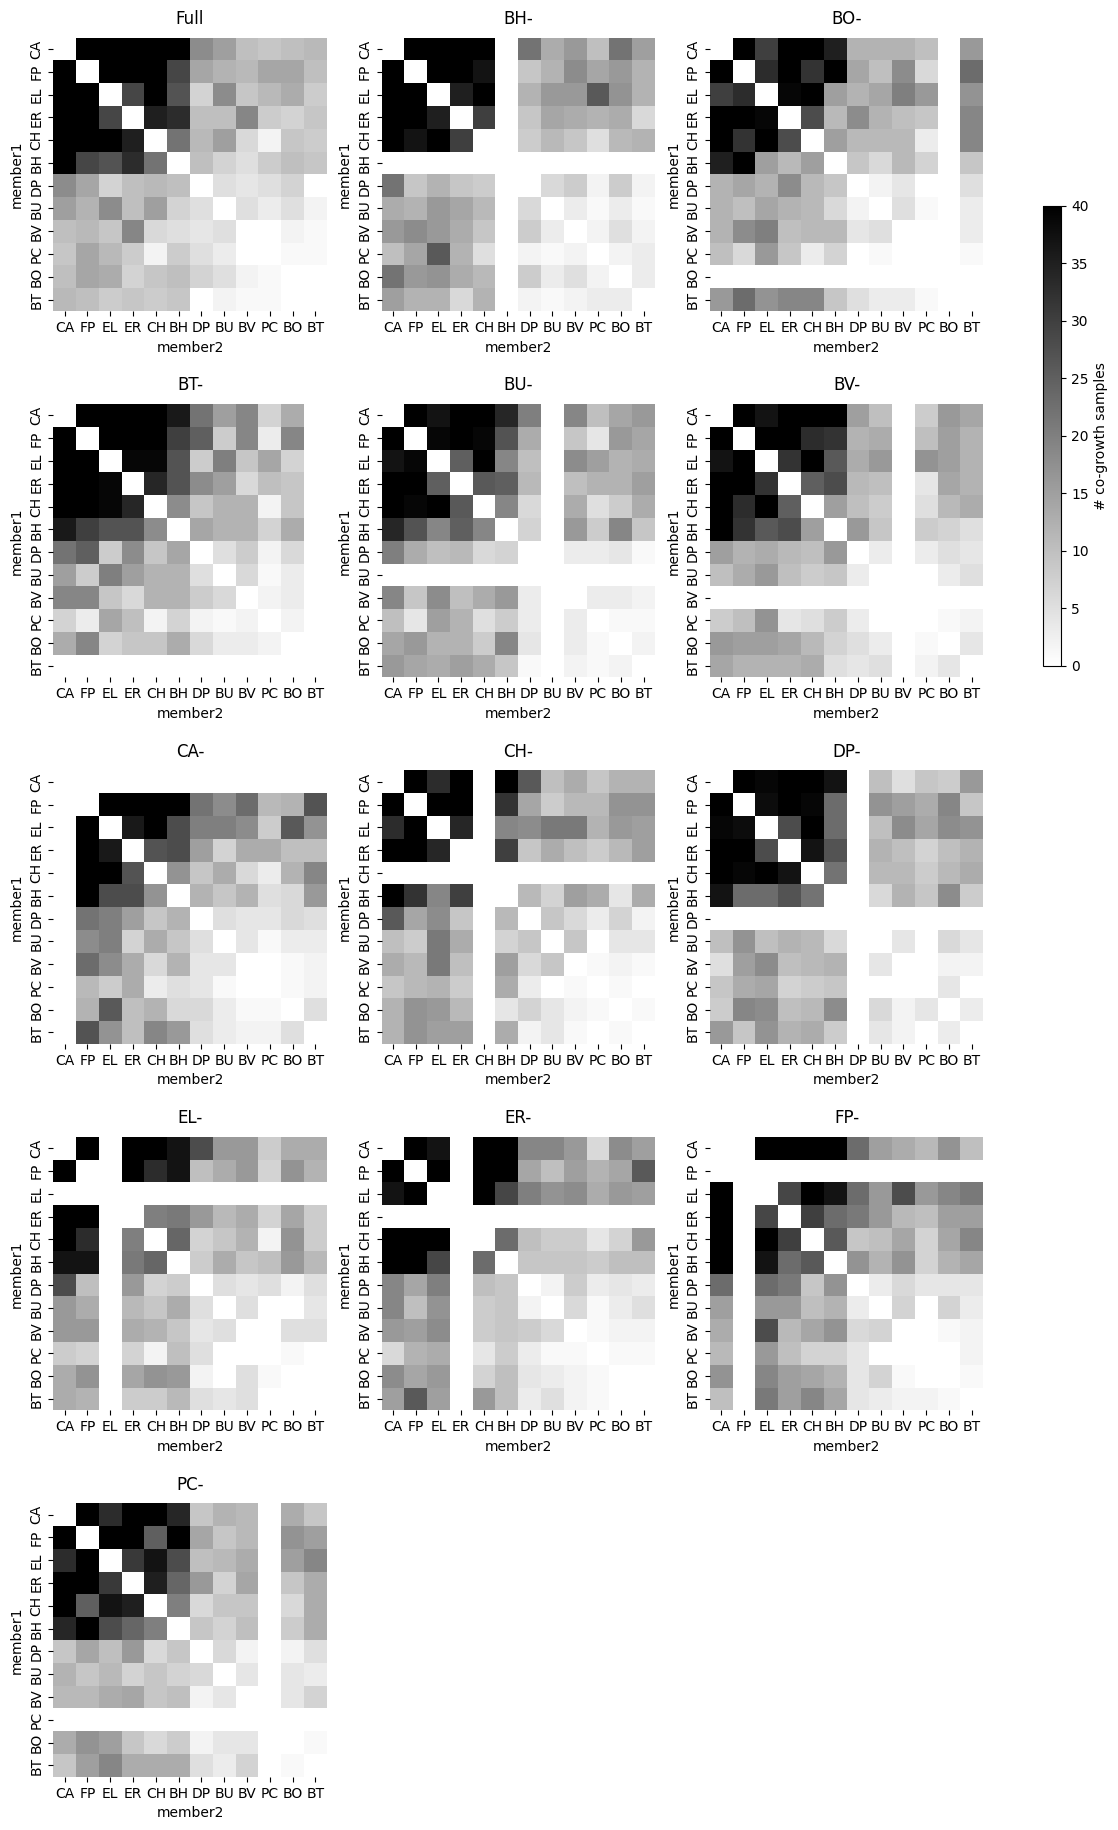

In [17]:
abundance_sim_analysis.plot_co_growth_count_venturelli(abundance_filtered)

### Correlating the output from different communities

In [8]:
communities = list(abundance_filtered.community.sort_values().unique())
communities.remove("NONE")

co_growth_count_none,member_abund_none = abundance_sim_analysis.make_co_growth_count_matrix(abundance_filtered,"NONE")
member_abund_dict = {}
spearman_corr = {}
member_abund_dict["None"]=member_abund_none

for i,community in enumerate(communities):

    co_growth_count_comm,member_abund = abundance_sim_analysis.make_co_growth_count_matrix(abundance_filtered,community)
    missing_member = community.replace("-","")
    
    # Remove row and column with missing member
    co_growth_count_none_copy = co_growth_count_none.copy()
    co_growth_count_none_copy = co_growth_count_none_copy.loc[co_growth_count_none_copy.index!=missing_member,co_growth_count_none_copy.index!=missing_member]
    
    co_growth_count_comm_copy = co_growth_count_comm.copy()
    co_growth_count_comm_copy = co_growth_count_comm_copy.loc[co_growth_count_comm_copy.index!=missing_member,co_growth_count_comm_copy.index!=missing_member]
    
    # Make series 
    series_none = co_growth_count_none_copy.stack()
    series_none.name ="NONE"
    series_comm = co_growth_count_comm_copy.stack()
    series_comm.name=community
    
    # Combne
    none_vs_comm = pd.concat([series_none,series_comm],axis=1)
    
    # Add spearman 
    array =none_vs_comm.values
    r, p = sp.stats.spearmanr(a=array)
    
    spearman_corr[community] = {"r":r,"p":p}
    member_abund_dict[community]=member_abund


#### Correlation with full community (interactions with missing member are excluded!)

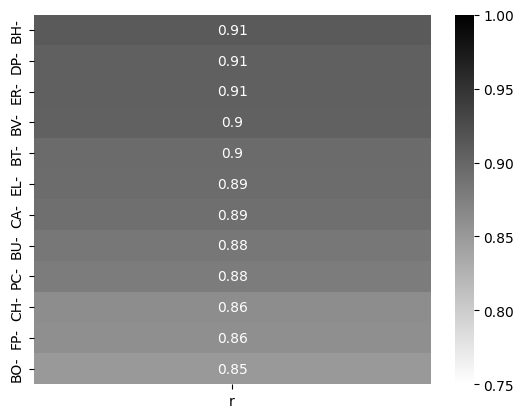

In [15]:
ax = sns.heatmap(pd.DataFrame(spearman_corr).T[["r"]].sort_values("r",ascending=False),cmap="binary",vmin=0.75,vmax=1,annot=True)

### Winners and loosers

#### Full community

<Axes: ylabel='member'>

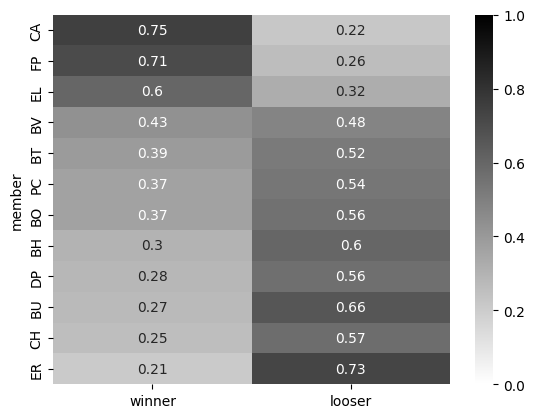

In [10]:
abundance_no_zeros = member_abund_none[member_abund_none>1e-6]
total_counts = abundance_no_zeros.count()

winner = abundance_no_zeros.eq(abundance_no_zeros.max(axis=1),axis=0).sum().sort_values()
winner = (winner/total_counts).sort_values()
winner.name="winner"

looser = abundance_no_zeros.eq(abundance_no_zeros.min(axis=1),axis=0).sum().sort_values()
looser = (looser/total_counts).sort_values()
looser.name="looser"

winner_looser = pd.concat([winner,looser],axis=1)
winner_looser = winner_looser.sort_values(by="winner",ascending=False)
sns.heatmap(winner_looser,cmap="binary",vmin=0,vmax=1,annot=True)

#### All communities

<Axes: ylabel='member'>

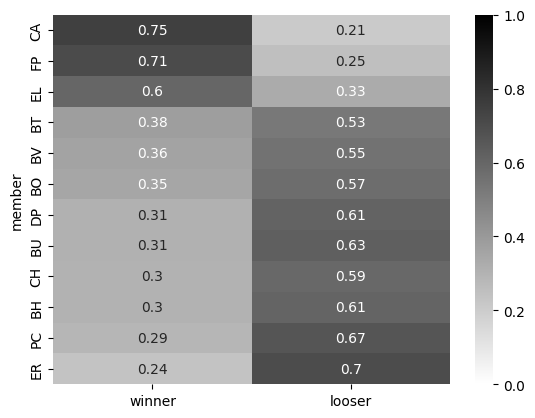

In [11]:
member_abund_all = pd.concat(member_abund_dict).fillna(0)
abundance_no_zeros = member_abund_all[member_abund_all>1e-6]
total_counts = abundance_no_zeros.count()

winner = abundance_no_zeros.eq(abundance_no_zeros.max(axis=1),axis=0).sum().sort_values()
winner = (winner/total_counts).sort_values()
winner.name="winner"

looser = abundance_no_zeros.eq(abundance_no_zeros.min(axis=1),axis=0).sum().sort_values()
looser = (looser/total_counts).sort_values()
looser.name="looser"

winner_looser = pd.concat([winner,looser],axis=1)
winner_looser = winner_looser.sort_values(by="winner",ascending=False)
sns.heatmap(winner_looser,cmap="binary",vmin=0,vmax=1,annot=True)

### Comparing relative abundance of co-growers vs non-co-growers

**Co-growers**: The members forming cluster in the clustermap of full community

**Independent growers**: The members not in cluster in clustermap.

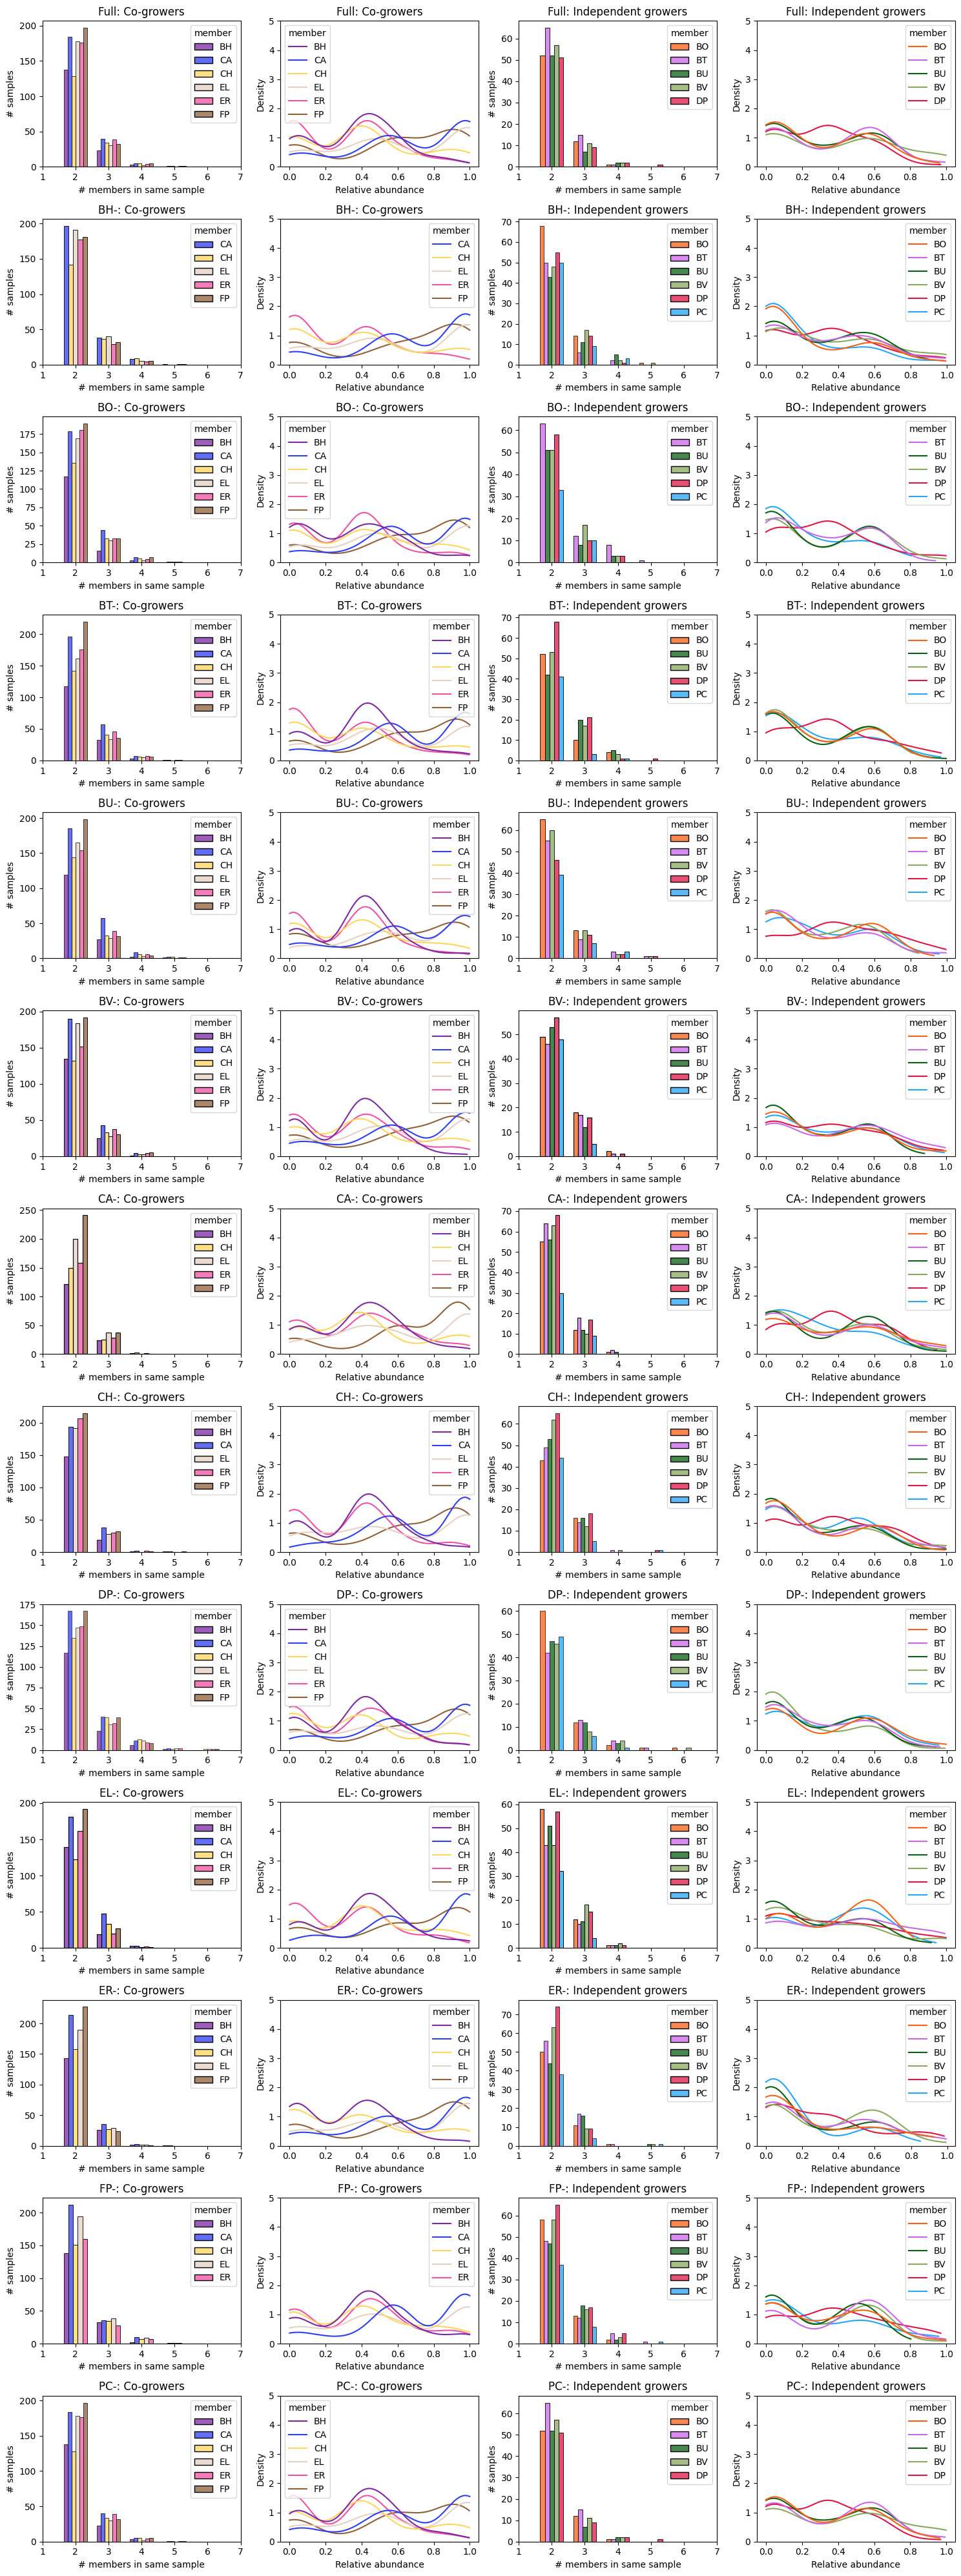

In [20]:

co_growers = set(["CH","EL","BH","ER","CA","FP"])

fig,axs =abundance_sim_analysis.plot_co_ind_growers_venturelli(abundance_filtered,co_growers=co_growers)